# Load & Inspect

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df_raw = pd.read_csv('sales_raw.csv')
print("--- Dataset Head ---")
print(df_raw.head())
print("\nShape:", df_raw.shape)
print("\nMissing Values:\n", df_raw.isna().sum())
print("Duplicate Rows:", df_raw.duplicated().sum())

--- Dataset Head ---
   transaction_id  sale_date region    category  quantity unit_price
0            1001  10/1/2026  North       food        2.0        120
1            1002  10/1/2026  South       Books       1.0        250
2            1003  10/2/2026  North        Food       3.0        110
3            1004  10/2/2026   East  Stationery       4.0         50
4            1005  10/3/2026  SOUTH       books       2.0        250

Shape: (21, 6)

Missing Values:
 transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1
dtype: int64
Duplicate Rows: 1


# Clean Dataset & Calculate Revenue

In [2]:
df_clean = df_raw.copy()

# Drop duplicates & clean string columns
df_clean = df_clean.drop_duplicates()
df_clean['region'] = df_clean['region'].astype(str).str.strip().str.title()
df_clean['category'] = df_clean['category'].astype(str).str.strip().str.title()
df_clean['region'] = df_clean['region'].replace({'Nan': np.nan, 'None': np.nan, '': np.nan})

# Clean numeric values
df_clean['unit_price'] = pd.to_numeric(df_clean['unit_price'], errors='coerce')
df_clean = df_clean[df_clean['quantity'] > 0]
df_clean = df_clean[df_clean['unit_price'] > 0]
df_clean = df_clean[df_clean['unit_price'] < 5000]
df_clean = df_clean.dropna(subset=['region', 'category'])

# Add Revenue
df_clean['revenue'] = df_clean['quantity'] * df_clean['unit_price']

# Save cleaned file
df_clean.to_csv('cleaned_sales.csv', index=False)
print("Cleaned rows:", len(df_clean))
print("cleaned_sales.csv saved successfully!")

Cleaned rows: 14
cleaned_sales.csv saved successfully!


# Groupby & Charts

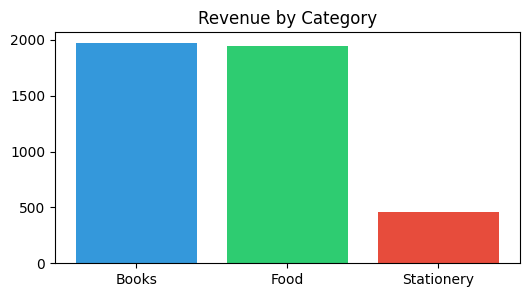

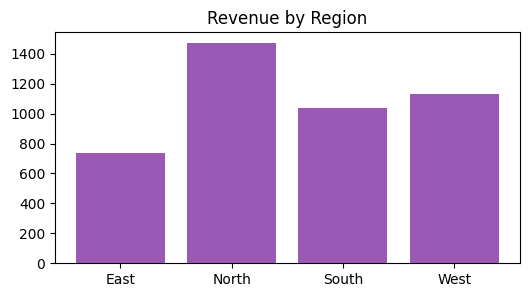

In [3]:
rev_by_cat = df_clean.groupby('category')['revenue'].sum().reset_index()
rev_by_reg = df_clean.groupby('region')['revenue'].sum().reset_index()

# Chart 1
plt.figure(figsize=(6, 3))
plt.bar(rev_by_cat['category'], rev_by_cat['revenue'], color=['#3498db', '#2ecc71', '#e74c3c'])
plt.title('Revenue by Category')
plt.savefig('chart1_revenue_by_category.png', bbox_inches='tight')
plt.show()

# Chart 2
plt.figure(figsize=(6, 3))
plt.bar(rev_by_reg['region'], rev_by_reg['revenue'], color='#9b59b6')
plt.title('Revenue by Region')
plt.savefig('chart2_revenue_by_region.png', bbox_inches='tight')
plt.show()

# CSV Manipulation

In [4]:
df_b = pd.read_csv('cleaned_sales.csv')

# Add tax amount
df_b['tax_amount'] = df_b['revenue'] * 0.05

# Increase Books price by 10%
books_mask = df_b['category'] == 'Books'
df_b.loc[books_mask, 'unit_price'] = df_b.loc[books_mask, 'unit_price'] * 1.10
df_b.loc[books_mask, 'revenue'] = df_b.loc[books_mask, 'quantity'] * df_b.loc[books_mask, 'unit_price']
df_b.loc[books_mask, 'tax_amount'] = df_b.loc[books_mask, 'revenue'] * 0.05

# Remove one transaction row & temporary column
df_b = df_b[df_b['transaction_id'] != 1014]
df_b['review_status'] = 'Pending'
df_b = df_b.drop(columns=['review_status'])

# Save updated file
df_b.to_csv('sales_updated.csv', index=False)
print("sales_updated.csv saved successfully!")
print(df_b.head())

sales_updated.csv saved successfully!
   transaction_id  sale_date region    category  quantity  unit_price  \
0            1001  10/1/2026  North        Food       2.0       120.0   
1            1002  10/1/2026  South       Books       1.0       275.0   
2            1003  10/2/2026  North        Food       3.0       110.0   
3            1004  10/2/2026   East  Stationery       4.0        50.0   
4            1005  10/3/2026  South       Books       2.0       275.0   

   revenue  tax_amount  
0    240.0       12.00  
1    275.0       13.75  
2    330.0       16.50  
3    200.0       10.00  
4    550.0       27.50  
